<a href="https://colab.research.google.com/github/SebastianoColombini/NN_DL_project/blob/main/v2.0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **IMPORT AND NETWORK VERSION**

In [ ]:
# Import section
from google.colab import drive
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import shutil
import zipfile
import time
import matplotlib.pyplot as plt
import random
import timm  # pretrained backbones (Swin / ViT / ...)

In [ ]:
# timm ships pretrained transformer backbones (Swin, ViT, ...)
!pip install -q timm

In [ ]:

version = {
    "version_name": "2.0",
    "backbone": "swin_tiny_patch4_window7_224",  # ImageNet-1k pretrained, ~28M params, fits T4 comfortably
    "lr": 3e-4,            # LR for the new decoder heads (trained from scratch, like v1.1)
    "backbone_lr": 3e-5,   # LR for the (partially) unfrozen backbone -- 10x lower, standard fine-tuning practice
    "freeze_backbone": True,
    "unfreeze_last_n_stages": 1,  # only fine-tune the deepest Swin stage; raise this (or set freeze_backbone=False) once the PoC is validated
    "epochs": 150,
    "batch_size": 128,
    "optimizer": "Adam",
    "patience": 15,
    "min_delta": 1e-4,
    "amp": True  # mixed precision: ~2x less VRAM and faster on the T4's tensor cores

}

## **SALICON DATASET LOADING**

In [ ]:
# Drive synchronization (where all versions and snapshots are saved)
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/NN_DL_Proj"
VERSION_DIR = os.path.join(DRIVE_DIR, version["version_name"])
SNAPSHOTS_DIR = os.path.join(VERSION_DIR, "snapshots")
DB_DRIVE_DIR = os.path.join(DRIVE_DIR, 'DB')

os.makedirs(VERSION_DIR, exist_ok=True)
os.makedirs(SNAPSHOTS_DIR, exist_ok=True)

LOCAL_DB_DIR = "/content/extracted_db"

# LOCAR_DB_DIR is cleaned every run
if os.path.exists(LOCAL_DB_DIR):
    print(f"Cleaning existing directory: {LOCAL_DB_DIR}")
    shutil.rmtree(LOCAL_DB_DIR)
os.makedirs(LOCAL_DB_DIR, exist_ok=True)

# Extract all datasets
def extract_dataset(zip_path, dest_dir):
    if os.path.exists(zip_path):
        print(f"Estrazione di {os.path.basename(zip_path)} in corso...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(dest_dir)
        print(f"Estrazione di {os.path.basename(zip_path)} completata.")
    else:
        print(f"ATTENZIONE: File {zip_path} non trovato.")

for zip_file in [f for f in os.listdir(DB_DRIVE_DIR) if f.endswith('.zip')]:
    extract_dataset(os.path.join(DB_DRIVE_DIR, zip_file), LOCAL_DB_DIR)

TRAIN_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'train')
TRAIN_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'train')
VAL_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'val')
VAL_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'val')

version_file_path = os.path.join(VERSION_DIR, "version.json")
with open(version_file_path, 'w') as f:
    json.dump(version, f, indent=4)

# Directories:
print(f"- TRAIN_IMAGES_DIR: {TRAIN_IMAGES_DIR}")
print(f"- TRAIN_SALIENCY_MAPS_DIR: {TRAIN_SALIENCY_MAPS_DIR}")
print(f"- VAL_IMAGES_DIR: {VAL_IMAGES_DIR}")
print(f"- VAL_SALIENCY_MAPS_DIR: {VAL_SALIENCY_MAPS_DIR}")

Mounted at /content/drive
Estrazione di images.zip in corso...
Estrazione di images.zip completata.
Estrazione di maps.zip in corso...
Estrazione di maps.zip completata.
- TRAIN_IMAGES_DIR: /content/extracted_db/images/train
- TRAIN_SALIENCY_MAPS_DIR: /content/extracted_db/maps/train
- VAL_IMAGES_DIR: /content/extracted_db/images/val
- VAL_SALIENCY_MAPS_DIR: /content/extracted_db/maps/val


In [ ]:

class SALICONDataset(Dataset):
    def __init__(self, image_root_dir, saliency_map_root_dir, transform=None):
        self.image_root_dir = image_root_dir
        self.saliency_map_root_dir = saliency_map_root_dir
        self.transform = transform

        VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

        # Delete non images from the dataset (.DS_Store, Thumbs.db, Jupyter checkpoints, etc.)
        image_files = sorted(f for f in os.listdir(image_root_dir) if f.lower().endswith(VALID_EXTS))
        map_files = sorted(f for f in os.listdir(saliency_map_root_dir) if f.lower().endswith(VALID_EXTS))

        assert len(image_files) == len(map_files), \
            f"Mismatch: {len(image_files)} images vs {len(map_files)} maps"

        # Verify that images match 1:1 with the related maps (same name)
        for img_f, map_f in zip(image_files, map_files):
            img_stem = os.path.splitext(img_f)[0]
            map_stem = os.path.splitext(map_f)[0]
            assert img_stem == map_stem, \
                f"Filename mismatch: image '{img_f}' vs map '{map_f}'"

        self.image_filenames = image_files
        self.saliency_map_filenames = map_files

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_name = os.path.join(self.image_root_dir, self.image_filenames[idx])
        saliency_name = os.path.join(self.saliency_map_root_dir, self.saliency_map_filenames[idx])

        image = Image.open(img_name).convert('RGB')
        saliency_map = Image.open(saliency_name).convert('L')

        if self.transform:
            image = self.transform(image)
            saliency_map = self.transform(saliency_map)

        return image, saliency_map

# 224x224 matches swin_tiny_patch4_window7_224's ImageNet pretraining resolution
transforms_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# DATALOADER initialization
train_salicon_dataset = SALICONDataset(
    image_root_dir=TRAIN_IMAGES_DIR,
    saliency_map_root_dir=TRAIN_SALIENCY_MAPS_DIR,
    transform=transforms_train
)
val_salicon_dataset = SALICONDataset(
    image_root_dir=VAL_IMAGES_DIR,
    saliency_map_root_dir=VAL_SALIENCY_MAPS_DIR,
    transform=transforms_train
)

print(f"Number of samples in SALICON training dataset: {len(train_salicon_dataset)}")
print(f"Number of samples in SALICON validation dataset: {len(val_salicon_dataset)}")

Number of samples in SALICON training dataset: 10000
Number of samples in SALICON validation dataset: 5000


## **MIT1003 TEST SET LOADING**

In [ ]:
MIT_DRIVE_DIR = os.path.join(DB_DRIVE_DIR, 'MIT_DATASET')
LOCAL_MIT_DIR = "/content/extracted_mit"

# LOCAL_MIT_DIR is cleaned every run
if os.path.exists(LOCAL_MIT_DIR):
    print(f"Cleaning existing directory: {LOCAL_MIT_DIR}")
    shutil.rmtree(LOCAL_MIT_DIR)
os.makedirs(LOCAL_MIT_DIR, exist_ok=True)

for zip_file in ['ALLSTIMULI.zip', 'ALLFIXATIONMAPS.zip']:
    extract_dataset(os.path.join(MIT_DRIVE_DIR, zip_file), LOCAL_MIT_DIR)

TEST_IMAGES_DIR = os.path.join(LOCAL_MIT_DIR, 'ALLSTIMULI')
TEST_SALIENCY_MAPS_DIR = os.path.join(LOCAL_MIT_DIR, 'ALLFIXATIONMAPS')

print(f"- TEST_IMAGES_DIR: {TEST_IMAGES_DIR}")
print(f"- TEST_SALIENCY_MAPS_DIR: {TEST_SALIENCY_MAPS_DIR}")

Estrazione di ALLSTIMULI.zip in corso...
Estrazione di ALLSTIMULI.zip completata.
Estrazione di ALLFIXATIONMAPS.zip in corso...
Estrazione di ALLFIXATIONMAPS.zip completata.
- TEST_IMAGES_DIR: /content/extracted_mit/ALLSTIMULI
- TEST_SALIENCY_MAPS_DIR: /content/extracted_mit/ALLFIXATIONMAPS


In [ ]:
class MITTestDataset(Dataset):
    """MIT1003 test set: pairs each stimulus with its continuous fixation map (name.jpeg <-> name_fixMap.jpg)."""
    def __init__(self, image_root_dir, saliency_map_root_dir, transform=None):
        self.image_root_dir = image_root_dir
        self.saliency_map_root_dir = saliency_map_root_dir
        self.transform = transform

        VALID_IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
        MAP_SUFFIX = '_fixMap.jpg'

        image_files = sorted(f for f in os.listdir(image_root_dir) if f.lower().endswith(VALID_IMG_EXTS))
        map_files_by_stem = {
            f[:-len(MAP_SUFFIX)]: f
            for f in os.listdir(saliency_map_root_dir) if f.endswith(MAP_SUFFIX)
        }

        self.samples = []
        for img_f in image_files:
            stem = os.path.splitext(img_f)[0]
            assert stem in map_files_by_stem, f"Missing fixation map for image '{img_f}'"
            self.samples.append((img_f, map_files_by_stem[stem]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_f, map_f = self.samples[idx]

        image = Image.open(os.path.join(self.image_root_dir, img_f)).convert('RGB')
        saliency_map = Image.open(os.path.join(self.saliency_map_root_dir, map_f)).convert('L')

        if self.transform:
            image = self.transform(image)
            saliency_map = self.transform(saliency_map)

        return image, saliency_map

# DATALOADER initialization
test_dataset = MITTestDataset(
    image_root_dir=TEST_IMAGES_DIR,
    saliency_map_root_dir=TEST_SALIENCY_MAPS_DIR,
    transform=transforms_train
)

print(f"Number of samples in MIT1003 test dataset: {len(test_dataset)}")

Number of samples in MIT1003 test dataset: 1003


## **NETWORK ARCHITECTURE**

**v2.0 change:** the Encoder is replaced by a pretrained
Swin-Tiny transformer backbone.

In [ ]:
# Pretrained transformer ENCODER (replaces the from-scratch 5-layer CNN encoder of v1.1)
class TransformerEncoder(nn.Module):
    """Swin-Tiny backbone (ImageNet-1k pretrained).

    Returns 3 feature maps at strides 8/16/32 (channels 192/384/768 for swin_tiny),
    matching the 3-branch deep-supervision decoder from v1.1.
    """
    def __init__(self, backbone_name="swin_tiny_patch4_window7_224",
                 freeze_backbone=True, unfreeze_last_n_stages=1):
        super().__init__()
        self.backbone = timm.create_model(
            backbone_name,
            pretrained=True,
            features_only=True,
            out_indices=(1, 2, 3),
        )
        self.out_channels = self.backbone.feature_info.channels()  # [192, 384, 768]
        self.out_strides = self.backbone.feature_info.reduction()  # [8, 16, 32]

        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False
            # Unfreeze the last N top-level modules (deepest stages) for fine-tuning
            if unfreeze_last_n_stages > 0:
                children = list(self.backbone.named_children())
                for name, module in children[-unfreeze_last_n_stages:]:
                    for p in module.parameters():
                        p.requires_grad = True

    # return 3 hierarchical feature maps (strides 8/16/32)
    def forward(self, x: torch.Tensor):
        a, b, c = self.backbone(x)
        # This Swin backbone returns NHWC tensors, while the Conv2d decoders expect NCHW --> convert explicitly.
        a = a.permute(0, 3, 1, 2).contiguous()
        b = b.permute(0, 3, 1, 2).contiguous()
        c = c.permute(0, 3, 1, 2).contiguous()
        return [a, b, c]

In [ ]:
# Sanity check: verify the backbone's output shapes/strides before wiring up the
# decoders below (channel order, NCHW vs NHWC, etc.).
_tmp_encoder = TransformerEncoder()
with torch.no_grad():
    _tmp_out = _tmp_encoder(torch.randn(1, 3, 224, 224))
print("Feature channels:", _tmp_encoder.out_channels)
print("Feature strides: ", _tmp_encoder.out_strides)
for i, f in enumerate(_tmp_out):
    print(f"  stage {i}: shape {tuple(f.shape)}")
del _tmp_encoder, _tmp_out

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Feature channels: [192, 384, 768]
Feature strides:  [8, 16, 32]
  stage 0: shape (1, 192, 28, 28)
  stage 1: shape (1, 384, 14, 14)
  stage 2: shape (1, 768, 7, 7)


In [ ]:
# DECODER layer-3 (stride-8 branch)
class Decoder3(nn.Module):
  def __init__(self, in_channels=192):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(in_channels, 64, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(64),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [ ]:
# DECODER layer-4 (stride-16 branch)
class Decoder4(nn.Module):
  def __init__(self, in_channels=384):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(in_channels, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [ ]:
# DECODER layer-5 (stride-32 branch)
class Decoder5(nn.Module):
  def __init__(self, in_channels=768):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(in_channels, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        # extra stage vs v1.1: input here is stride-32 (not stride-16), so one more x2 is needed to reach full resolution
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [ ]:
# Final layer to combine the 3 saliency maps
class FinalCov(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.ConvTranspose2d(3, 1, kernel_size=1, stride=1, padding=0),
        nn.Sigmoid()
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)


## **LOSS FUNCTION**

In [ ]:
def normalize_map(s_map):
    """Normalizes the map so that the sum of all pixels is equal to 1 (probability distribution)"""
    batch_size = s_map.size(0)
    s_map_flat = s_map.view(batch_size, -1)
    # Avoid division by zero by adding a small epsilon
    s_map_sum = torch.sum(s_map_flat, dim=1, keepdim=True) + 1e-7
    s_map_norm = s_map_flat / s_map_sum
    return s_map_norm.view_as(s_map)

def kld_loss(pred, gt):
    """Kullback-Leibler Divergence Loss"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)
    eps = 1e-7
    # KLD formula: Sum(GT * log(GT / (Pred + eps)))
    loss = gt * torch.log(gt / (pred + eps) + eps)
    return torch.mean(torch.sum(loss.view(loss.size(0), -1), dim=1))

def cc_loss(pred, gt):
    """Pearson Correlation Coefficient Loss (expressed as 1 - CC to minimize it)"""
    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Compute the mean values
    pred_mean = torch.mean(pred_flat, dim=1, keepdim=True)
    gt_mean = torch.mean(gt_flat, dim=1, keepdim=True)

    # Center the values by subtracting the mean
    pred_center = pred_flat - pred_mean
    gt_center = gt_flat - gt_mean

    # Pearson correlation formula
    cc_num = torch.sum(pred_center * gt_center, dim=1)
    cc_den = torch.sqrt(torch.sum(pred_center ** 2, dim=1) * torch.sum(gt_center ** 2, dim=1) + 1e-7)

    cc = cc_num / cc_den
    return torch.mean(1 - cc) # Vogliamo massimizzare CC, quindi minimizziamo (1 - CC)

def sim_loss(pred, gt):
    """Histogram Similarity Loss (expressed as 1 - SIM)"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)

    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Compute the pixel-wise minimum between the two normalized distributions
    sim = torch.sum(torch.min(pred_flat, gt_flat), dim=1)
    return torch.mean(1 - sim)

def single_loss(pred, gt, w_kld=1.0, w_cc=1.0, w_sim=1.0):
    """Combines the three losses for a single branch"""
    return w_kld * kld_loss(pred, gt) + w_cc * cc_loss(pred, gt) + w_sim * sim_loss(pred, gt)

def total_loss(final_map, s1, s2, s3, gt):
    """Computes the total loss by applying Deep Supervision to all branches"""
    l_final = single_loss(final_map, gt)
    l_s1 = single_loss(s1, gt)
    l_s2 = single_loss(s2, gt)
    l_s3 = single_loss(s3, gt)

    # Sum all losses
    return l_final + l_s1 + l_s2 + l_s3

## **MAIN TRAINING PHASE**

In [ ]:
if torch.cuda.is_available():
        torch.cuda.empty_cache()

batch_size = version["batch_size"]
total_epochs = version["epochs"]
lr = version["lr"]
backbone_lr = version["backbone_lr"]
use_amp = version["amp"] and torch.cuda.is_available()

# Early stopping
patience = version["patience"]
min_delta = version["min_delta"]

encoder = TransformerEncoder(
    backbone_name=version["backbone"],
    freeze_backbone=version["freeze_backbone"],
    unfreeze_last_n_stages=version["unfreeze_last_n_stages"],
)

decoder3 = Decoder3(in_channels=encoder.out_channels[0])
decoder4 = Decoder4(in_channels=encoder.out_channels[1])
decoder5 = Decoder5(in_channels=encoder.out_channels[2])
final = FinalCov()

# Differential learning rates: the pretrained backbone gets a much smaller LR than
# the randomly-initialized decoder heads, which is standard practice when fine-tuning.
optimizer = optim.Adam([
    {"params": [p for p in encoder.parameters() if p.requires_grad], "lr": backbone_lr},
    {"params": (list(decoder3.parameters()) + list(decoder4.parameters()) +
                list(decoder5.parameters()) + list(final.parameters())), "lr": lr},
])
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

train_dataloader = DataLoader(train_salicon_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_dataloader = DataLoader(val_salicon_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# load on GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
encoder.to(device)
decoder3.to(device)
decoder4.to(device)
decoder5.to(device)
final.to(device)

# Snapshot logic (latest to resume training)
encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_latest.pth")
decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_latest.pth")
decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_latest.pth")
decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_latest.pth")
final_path = os.path.join(SNAPSHOTS_DIR, f"final_latest.pth")
optimizer_path = os.path.join(SNAPSHOTS_DIR, f"optimizer_latest.pth")
progress_json_path = os.path.join(SNAPSHOTS_DIR, f"progress_latest.json")

# Snapshot logic (best for early stopping)
best_encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_best.pth")
best_decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_best.pth")
best_decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_best.pth")
best_decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_best.pth")
best_final_path = os.path.join(SNAPSHOTS_DIR, f"final_best.pth")

train_losses_history = []
val_losses_history = []
best_val_loss = float('inf')
epochs_no_improve = 0
best_epoch = 0

# Resume training if snapshot exists
start_epoch = 0
if os.path.exists(progress_json_path):
    print("Found existing snapshot. Resuming training...")
    with open(progress_json_path, 'r') as f:
        epoch_data = json.load(f)
    start_epoch = epoch_data['epoch']
    train_losses_history = epoch_data['train_losses_history']
    val_losses_history = epoch_data['val_losses_history']

    # Load data for early stopping
    best_val_loss = epoch_data.get('best_val_loss', min(val_losses_history) if val_losses_history else float('inf'))
    epochs_no_improve = epoch_data.get('epochs_no_improve', 0)
    best_epoch = epoch_data.get('best_epoch', 0)

    # Load model states (latest checkpoint to resume training)
    encoder.load_state_dict(torch.load(encoder_path))
    decoder3.load_state_dict(torch.load(decoder3_path))
    decoder4.load_state_dict(torch.load(decoder4_path))
    decoder5.load_state_dict(torch.load(decoder5_path))
    final.load_state_dict(torch.load(final_path))

    # Load optimizer state
    optimizer.load_state_dict(torch.load(optimizer_path))

    print(f"Resuming from Epoch {start_epoch+1}. Best val loss so far: {best_val_loss:.4f} "
          f"(epoch {best_epoch}), no improvement for {epochs_no_improve} epoch(s).")


# Main loop
for epoch in range(start_epoch, total_epochs):
    # Training phase
    encoder.train()
    decoder3.train()
    decoder4.train()
    decoder5.train()
    final.train()

    total_train_loss_epoch = 0.0

    # TRAINING
    for i, (image_batch, saliency_map_batch) in enumerate(train_dataloader): # gather the batch

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        image_batch = image_batch.to(device)
        saliency_map_batch = saliency_map_batch.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast('cuda', enabled=use_amp):
            latent_features = encoder(image_batch)
            saliency_3 = decoder3(latent_features[0])
            saliency_4 = decoder4(latent_features[1])
            saliency_5 = decoder5(latent_features[2])
            fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
            final_saliency_map = final(fused_input)

            # Calculate the training loss
            loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_train_loss_epoch += loss.item()
        if (i + 1) % 10 == 0: # Print every 10 mini-batches
            print(f"Epoch [{epoch+1}/{total_epochs}], Step [{i+1}/{len(train_dataloader)}], Train Loss: {total_train_loss_epoch/(i+1):.4f}")

    avg_train_loss_epoch = total_train_loss_epoch / len(train_dataloader)
    train_losses_history.append(avg_train_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Train Loss: {avg_train_loss_epoch:.4f}")

    # VALIDATION
    encoder.eval()
    decoder3.eval()
    decoder4.eval()
    decoder5.eval()
    final.eval()

    total_val_loss_epoch = 0.0
    with torch.no_grad():
        for i, (image_batch, saliency_map_batch) in enumerate(val_dataloader):
            image_batch = image_batch.to(device)
            saliency_map_batch = saliency_map_batch.to(device)

            with torch.amp.autocast('cuda', enabled=use_amp):
                latent_features = encoder(image_batch)
                saliency_3 = decoder3(latent_features[0])
                saliency_4 = decoder4(latent_features[1])
                saliency_5 = decoder5(latent_features[2])
                fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
                final_saliency_map = final(fused_input)

                # Calculate the validation loss
                loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)

            total_val_loss_epoch += loss.item()

    avg_val_loss_epoch = total_val_loss_epoch / len(val_dataloader)
    val_losses_history.append(avg_val_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Validation Loss: {avg_val_loss_epoch:.4f}")

    # Early stopping
    if avg_val_loss_epoch < best_val_loss - min_delta:
        print(f"Val loss improved: {best_val_loss:.4f} -> {avg_val_loss_epoch:.4f}. Saved as best checkpoint.")
        best_val_loss = avg_val_loss_epoch
        best_epoch = epoch + 1
        epochs_no_improve = 0

        torch.save(encoder.state_dict(), best_encoder_path)
        torch.save(decoder3.state_dict(), best_decoder3_path)
        torch.save(decoder4.state_dict(), best_decoder4_path)
        torch.save(decoder5.state_dict(), best_decoder5_path)
        torch.save(final.state_dict(), best_final_path)
    else:
        epochs_no_improve += 1
        print(f"No improvement in {epochs_no_improve} epochs (best: {best_val_loss:.4f} @ epoch {best_epoch}).")

    # Save checkpoint (latest to resume training)
    torch.save(encoder.state_dict(), encoder_path)
    torch.save(decoder3.state_dict(), decoder3_path)
    torch.save(decoder4.state_dict(), decoder4_path)
    torch.save(decoder5.state_dict(), decoder5_path)
    torch.save(final.state_dict(), final_path)
    torch.save(optimizer.state_dict(), optimizer_path)

    # Prepare data for JSON
    epoch_data = {
        "epoch": epoch + 1,
        "train_losses_history": train_losses_history,
        "val_losses_history": val_losses_history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_no_improve": epochs_no_improve,
        "model_snapshots": {
            "encoder": encoder_path,
            "decoder3": decoder3_path,
            "decoder4": decoder4_path,
            "decoder5": decoder5_path,
            "final": final_path,
            "optimizer": optimizer_path,
            "encoder_best": best_encoder_path,
            "decoder3_best": best_decoder3_path,
            "decoder4_best": best_decoder4_path,
            "decoder5_best": best_decoder5_path,
            "final_best": best_final_path
        }
    }

    # Save progress to JSON
    with open(progress_json_path, 'w') as f:
        json.dump(epoch_data, f, indent=4)

    print(f"Epoch {epoch+1} data and models saved to {SNAPSHOTS_DIR} (latest + best)")

    # Early stopping: stopping condition
    if epochs_no_improve >= patience:
        print(f"\nEarly stopping occurred on epoch {epoch+1}: no improvement of "
              f"val loss in {epochs_no_improve} epochs (best: {best_val_loss:.4f} @ epoch {best_epoch}).")
        break

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Found existing snapshot. Resuming training...
Resuming from Epoch 106. Best val loss so far: 3.2002 (epoch 103), no improvement for 2 epoch(s).


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [106/150], Step [10/79], Train Loss: 2.4870
Epoch [106/150], Step [20/79], Train Loss: 2.4710
Epoch [106/150], Step [30/79], Train Loss: 2.4624
Epoch [106/150], Step [40/79], Train Loss: 2.4629
Epoch [106/150], Step [50/79], Train Loss: 2.4610
Epoch [106/150], Step [60/79], Train Loss: 2.4612
Epoch [106/150], Step [70/79], Train Loss: 2.4663
Epoch [106/150], Average Train Loss: 2.4664
Epoch [106/150], Average Validation Loss: 3.2353
No improvement in 3 epochs (best: 3.2002 @ epoch 103).
Epoch 106 data and models saved to /content/drive/MyDrive/NN_DL_Proj/2.0/snapshots (latest + best)
Epoch [107/150], Step [10/79], Train Loss: 2.3953
Epoch [107/150], Step [20/79], Train Loss: 2.4242
Epoch [107/150], Step [30/79], Train Loss: 2.4323
Epoch [107/150], Step [40/79], Train Loss: 2.4321
Epoch [107/150], Step [50/79], Train Loss: 2.4366
Epoch [107/150], Step [60/79], Train Loss: 2.4419
Epoch [107/150], Step [70/79], Train Loss: 2.4488
Epoch [107/150], Average Train Loss: 2.4498
Epoch [10

KeyboardInterrupt: 

## **TESTING AND EVALUATION**

In [ ]:
# Load the best checkpoint (not the latest because early stopping) for testing/inference

encoder.load_state_dict(torch.load(best_encoder_path))
decoder3.load_state_dict(torch.load(best_decoder3_path))
decoder4.load_state_dict(torch.load(best_decoder4_path))
decoder5.load_state_dict(torch.load(best_decoder5_path))
final.load_state_dict(torch.load(best_final_path))

print(f"Best checkpoint loaded ({best_epoch} epoch, val loss {best_val_loss:.4f}).")

Best checkpoint loaded (127 epoch, val loss 3.1278).


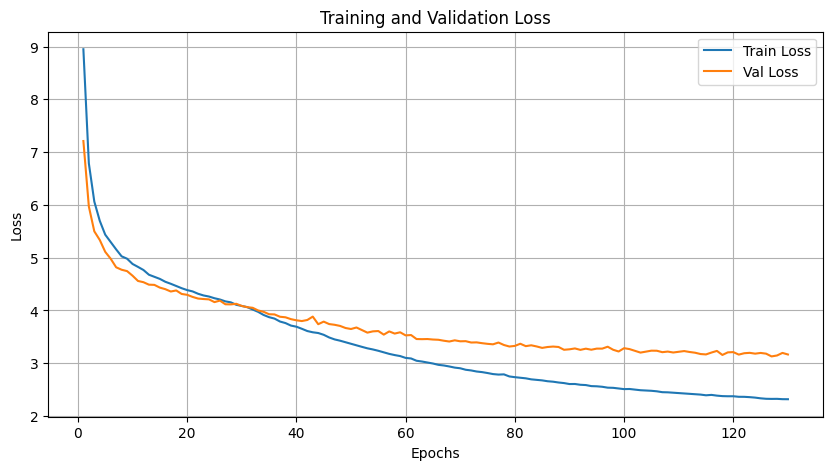

In [ ]:
# Plotting Train/Validation losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_history) + 1), train_losses_history, label='Train Loss')
plt.plot(range(1, len(val_losses_history) + 1), val_losses_history, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

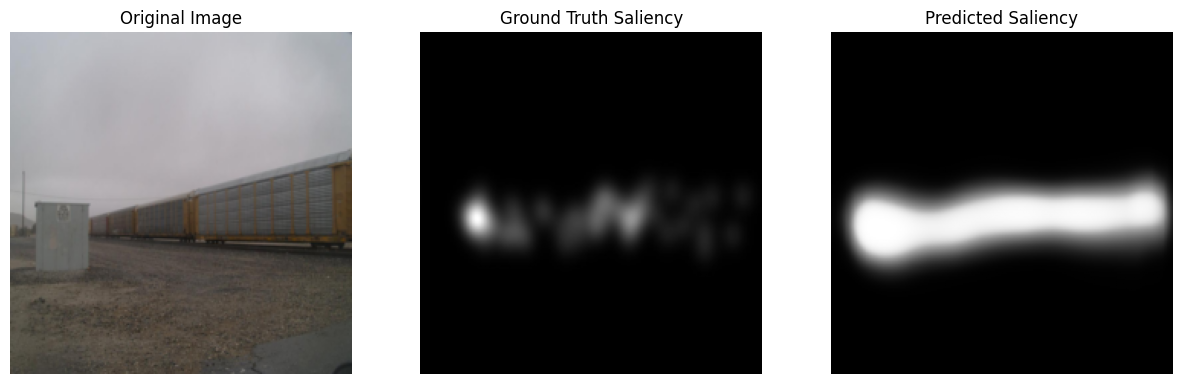

In [ ]:
with torch.no_grad():
    img_idx = 0

    # first element of the last image batch
    sample_img = image_batch[img_idx].cpu()
    sample_gt = saliency_map_batch[img_idx].cpu()
    sample_pred = final_saliency_map[img_idx].cpu()

    # Unnormalize image for visualization
    img_display = sample_img.permute(1, 2, 0).numpy()
    gt_display = sample_gt.squeeze().numpy()
    pred_display = sample_pred.squeeze().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(gt_display, cmap='gray')
    axes[1].set_title('Ground Truth Saliency')
    axes[1].axis('off')

    axes[2].imshow(pred_display, cmap='gray')
    axes[2].set_title('Predicted Saliency')
    axes[2].axis('off')

    plt.show()

In [ ]:
# Quantitative evaluation on the held-out MIT1003 test set (never seen during training)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

encoder.eval()
decoder3.eval()
decoder4.eval()
decoder5.eval()
final.eval()

total_test_loss = 0.0
total_kld, total_cc, total_sim = 0.0, 0.0, 0.0
n_batches = 0

with torch.no_grad():
    for image_batch, saliency_map_batch in test_dataloader:
        image_batch = image_batch.to(device)
        saliency_map_batch = saliency_map_batch.to(device)

        latent_features = encoder(image_batch)
        saliency_3 = decoder3(latent_features[0])
        saliency_4 = decoder4(latent_features[1])
        saliency_5 = decoder5(latent_features[2])
        fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
        final_saliency_map = final(fused_input)

        loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)
        total_test_loss += loss.item()

        total_kld += kld_loss(final_saliency_map, saliency_map_batch).item()
        total_cc += (1 - cc_loss(final_saliency_map, saliency_map_batch)).item()
        total_sim += (1 - sim_loss(final_saliency_map, saliency_map_batch)).item()
        n_batches += 1

avg_test_loss = total_test_loss / n_batches

print(f"MIT1003 Test Set - Total Loss: {avg_test_loss:.4f} (comparable to Train/Val Loss above)")
print(f"MIT1003 Test Set - KLD: {total_kld / n_batches:.4f} (lower is better)")
print(f"MIT1003 Test Set - CC:  {total_cc / n_batches:.4f} (higher is better)")
print(f"MIT1003 Test Set - SIM: {total_sim / n_batches:.4f} (higher is better)")

MIT1003 Test Set - Total Loss: 7.5088 (comparable to Train/Val Loss above)
MIT1003 Test Set - KLD: 0.9436 (lower is better)
MIT1003 Test Set - CC:  0.5929 (higher is better)
MIT1003 Test Set - SIM: 0.4609 (higher is better)


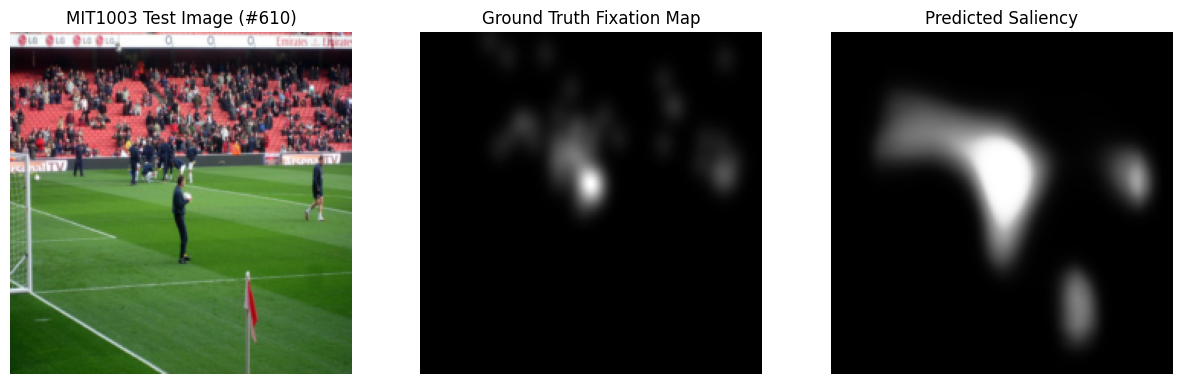

In [ ]:
# Qualitative check on a random MIT1003 test sample (Original / Ground Truth / Predicted)
encoder.eval()
decoder3.eval()
decoder4.eval()
decoder5.eval()
final.eval()

with torch.no_grad():
    idx = random.randrange(len(test_dataset))
    sample_img, sample_gt = test_dataset[idx]

    input_tensor = sample_img.unsqueeze(0).to(device)

    latent = encoder(input_tensor)
    s3 = decoder3(latent[0])
    s4 = decoder4(latent[1])
    s5 = decoder5(latent[2])
    fused = torch.cat((s3, s4, s5), dim=1)
    prediction = final(fused)

    img_display = sample_img.permute(1, 2, 0).numpy()
    gt_display = sample_gt.squeeze().numpy()
    pred_display = prediction.squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title(f"MIT1003 Test Image (#{idx})")
    axes[0].axis('off')

    axes[1].imshow(gt_display, cmap='gray')
    axes[1].set_title('Ground Truth Fixation Map')
    axes[1].axis('off')

    axes[2].imshow(pred_display, cmap='gray')
    axes[2].set_title('Predicted Saliency')
    axes[2].axis('off')

    plt.show()